# Midspan Deflection of a 23-Bar Plane Truss with Lognormal Stiffnesses and Gumbel Loads

__Paper:__ G. Blatman<sup>a,b</sup> and B. Sudret<sup>a,c</sup>, "Adaptive sparse polynomial chaos expansion based on least angle regression", *Journal of Computational Physics* 230 (2011) 2345–2367, [doi:10.1016/j.jcp.2010.12.021](https://doi.org/10.1016/j.jcp.2010.12.021) [[1]](#References)

<sup>a</sup> Clermont Université, IFMA, EA 3867, Laboratoire de Mécanique et Ingénieries, Clermont-Ferrand, France
<sup>b</sup> EDF R&D, Département Matériaux et Mécanique des Composants, Site des Renardières, Moret-sur-Loing, France
<sup>c</sup> Phimeca Engineering, Cournon d'Auvergne, France

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

It runs in Python 3 with numpy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes about half a minute.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import truss_model as tm

warnings.filterwarnings('ignore', category=ac.ActiveSubspacesWarning)
SEED = 2011                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels = [r'$E_1$', r'$E_2$', r'$A_1$', r'$A_2$'] + [f'$P_{j}$' for j in range(1, 7)]

### Summary

A simply supported plane truss of 23 linear-elastic bars (span 24 m, height 2 m) carries six random vertical loads, and its Young's moduli and cross-section areas are random, ten independent lognormal and Gumbel inputs in all, as in the truss example of Blatman and Sudret [1] (Sec. 6.3); the quantity of interest is the downward deflection $V_1$ at midspan. We compute the active subspace in the paper's own standard-normal coordinates (every input mapped through its CDF, Eq. (55)) from 1000 Monte Carlo samples with exact adjoint gradients, and find a one-dimensional active subspace with $\lambda_1/\lambda_2 = 105.49$ and 97.558 % of the trace in $\lambda_1$, along which a quadratic has leave-one-out $R^2 = 0.9873$. The normalized activity scores of that one direction agree with the paper's reference total Sobol' indices (Table 2) to within 0.0148 (largest for $A_1$) and with our own Jansen estimates to within 0.0039, and the paper's reference values for $A_1$ (0.388) and $E_1$ (0.367), which are equal in exact arithmetic, differ by about the sampling error of a Homma–Saltelli-type pick-freeze estimator with $N = 5\times10^5$ base samples (sd 0.0092 for $A_1$ and 0.010 for $E_1$), not by that of a Jansen estimator of the same size (sd 0.0010; `check_accuracy.py`, check 3).

### Active subspaces in brief

For a function $f(\boldsymbol\xi)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\boldsymbol\xi = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\boldsymbol\xi$ and is nearly constant along $\mathbf W_2^T\boldsymbol\xi$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015 [[2]](#References).

### The model

**Structure** (Sec. 6.3.1 and Fig. 8, pp. 2357–2358 of [1]). A plane truss of span 24 m and height 2 m has 23 members, "11 horizontal bars and 12 oblical bars", and is modelled with 23 bar elements. Reading Fig. 8: the bottom chord has 7 nodes at $x = 0, 4, \dots, 24$ m, the top chord 6 nodes at $x = 2, 6, \dots, 22$ m, each top node is joined to the two bottom nodes below it, the left end is pinned and the right end is on a roller. The six vertical loads $P_1,\dots,P_6$ act downward at the top nodes, and the response is the deflection $V_1$ at midspan (the bottom node at $x = 12$ m), here in metres and positive downward. The horizontal bars have Young's modulus $E_1$ and area $A_1$, the oblique bars $E_2$ and $A_2$ (p. 2358). The paper gives no node or connectivity table; the numbering and supports are this notebook's reading of Fig. 8.

**Finite elements.** Linear-elastic two-node bar elements with small displacements, 26 degrees of freedom less 3 supported, so $\mathbf K\mathbf u = \mathbf f$ with

$$
\mathbf K = E_1A_1\,\mathbf K_h + E_2A_2\,\mathbf K_d,\qquad V_1 = -\mathbf q^T\mathbf u ,
$$

where $\mathbf K_h$ and $\mathbf K_d$ assemble the unit-property element matrices $\mathbf c\mathbf c^T/L_e$ of the horizontal and oblique bars and $\mathbf q$ picks the vertical displacement of the midspan node. Gradients are exact, from one adjoint solve $\mathbf K\boldsymbol\lambda = \mathbf q$: $\partial V_1/\partial E_1 = A_1\,\boldsymbol\lambda^T\mathbf K_h\mathbf u$, $\partial V_1/\partial A_1 = E_1\,\boldsymbol\lambda^T\mathbf K_h\mathbf u$ (likewise $E_2, A_2$ with $\mathbf K_d$), and $\partial V_1/\partial P_j = \lambda$ at the vertical degree of freedom of top node $j$ (`truss_model.deflection`).

**Exact structure.** The truss is statically determinate (23 bar forces and 3 reactions from 26 equilibrium equations), so by the unit-load method $V_1 = \sum_j P_j\,(a_j/(E_1A_1) + b_j/(E_2A_2))$ with constants $a_j, b_j$ that follow from equilibrium alone; the paper notes that $V_1$ depends on the moduli and areas only through $E_1A_1$ and $E_2A_2$ (p. 2358). `truss_model.virtual_work` computes $V_1$ this way, without the stiffness matrix, as a check below.

**Inputs** (Table 1, p. 2358; independent, Eq. (54)). Lognormal and Gumbel distributions are given by mean and standard deviation; we take the Gumbel as the distribution of the largest value, $F(z) = \exp(-e^{-(z-u)/\beta})$ with $\beta = \sigma\sqrt6/\pi$ and $u = \mu - \gamma_E\beta$ (the paper does not write out the parameterization).

In [2]:
print(f"{'input':5s} {'distribution':13s} {'mean':>10s} {'sd':>10s}  {'units':5s} description")
for j, n in enumerate(tm.NAMES):
    print(f'{n:5s} {tm.DISTRIBUTIONS[j]:13s} {tm.MEAN[j]:10.3g} {tm.SD[j]:10.3g}  {tm.UNITS[j]:5s} {tm.DESCRIPTIONS[j]}')
print('\nlognormal ln-sd s (E, A):', np.array2string(tm.LN_S[:4], precision=6),
      f'; Gumbel beta = {tm.GUM_BETA[4]:.2f} N, u = {tm.GUM_U[4]:.2f} N')
print(f'V1 at the input means: {tm.deflection(tm.MEAN)[0]:.6f} m (unit-load method: {tm.virtual_work(tm.MEAN):.6f} m)')
N_bar, R = tm.bar_forces(tm.MEAN[4:])
print(f'support reactions at the mean loads (N): {np.array2string(R, precision=1)}; sum of loads {tm.MEAN[4:].sum():.1f} N')

input distribution        mean         sd  units description
E1    lognormal        2.1e+11    2.1e+10  Pa    Young's modulus of the 11 horizontal bars
E2    lognormal        2.1e+11    2.1e+10  Pa    Young's modulus of the 12 diagonal bars
A1    lognormal          0.002     0.0002  m^2   cross-section area of the 11 horizontal bars
A2    lognormal          0.001     0.0001  m^2   cross-section area of the 12 diagonal bars
P1    Gumbel (max)       5e+04    7.5e+03  N     vertical (downward) load at top node 1 (x = 2 m)
P2    Gumbel (max)       5e+04    7.5e+03  N     vertical (downward) load at top node 2 (x = 6 m)
P3    Gumbel (max)       5e+04    7.5e+03  N     vertical (downward) load at top node 3 (x = 10 m)
P4    Gumbel (max)       5e+04    7.5e+03  N     vertical (downward) load at top node 4 (x = 14 m)
P5    Gumbel (max)       5e+04    7.5e+03  N     vertical (downward) load at top node 5 (x = 18 m)
P6    Gumbel (max)       5e+04    7.5e+03  N     vertical (downward) load at top

**Coordinates (scaling).** Following the paper's Eq. (55), every input is mapped through its own CDF to a standard normal variable, $\xi_i = \Phi^{-1}(F_{Z_i}(Z_i))$, so $Z_i = F_{Z_i}^{-1}(\Phi(\xi_i))$: $Z = e^{\mu + s\xi}$ for the lognormals and $Z = u - \beta\ln(-\ln\Phi(\xi))$ for the Gumbels. All ten inputs are scaled the same way (through the CDF, not by the standard deviation), and the active subspace is computed in $\boldsymbol\xi$, where the joint density is $N(\mathbf 0, \mathbf I_{10})$. Gradients map by the diagonal chain rule $\partial V_1/\partial\xi_i = (\partial V_1/\partial Z_i)\,dZ_i/d\xi_i$ (`truss_model.dphysical_dxi`). Because $E_1$ and $A_1$ are lognormal with the same coefficient of variation (0.1) and enter only as $E_1A_1$, $\partial V_1/\partial\xi_{E_1} = s\,E_1\,\partial V_1/\partial E_1 = s\,A_1\,\partial V_1/\partial A_1 = \partial V_1/\partial\xi_{A_1}$ at every point, and likewise for $E_2, A_2$: two eigenvalues of $\mathbf C$ are zero in exact arithmetic.

### Load data

`generate_data.py` drew $M = 1000$ independent Monte Carlo samples $\boldsymbol\xi \sim N(\mathbf 0, \mathbf I_{10})$ (`numpy.random.default_rng(2011)`; not Latin hypercube), mapped them to the physical inputs, and wrote the inputs in both coordinates, the deflection and its exact gradient with respect to the physical inputs.

In [3]:
Z = np.loadtxt('inputs.csv', delimiter=',')             # (M, 10) physical inputs E1, E2, A1, A2 (Pa, m^2), P1..P6 (N)
XI = np.loadtxt('inputs_standard.csv', delimiter=',')   # (M, 10) the same samples in standard-normal coordinates
V = np.loadtxt('outputs.csv', delimiter=',')            # (M,) midspan deflection V1 (m)
G = np.loadtxt('gradients.csv', delimiter=',')          # (M, 10) dV1/dZ (physical units)
M, m = Z.shape
G_xi = G * tm.dphysical_dxi(XI)                         # dV1/dxi
print(f'inputs {Z.shape}, inputs_standard {XI.shape}, outputs {V.shape}, gradients {G.shape}')

inputs (1000, 10), inputs_standard (1000, 10), outputs (1000,), gradients (1000, 10)


We check the files against the model and against the unit-load method, the gradients against central differences in $\boldsymbol\xi$, the transform against the Gumbel CDF, and the sample against the stated moments, and count samples outside physical meaning (non-positive loads, moduli or areas).

In [4]:
print(f'max |physical(xi) - Z| / |Z|: {np.max(np.abs(tm.physical(XI) / Z - 1)):.1e}')
print(f'max |model - file| / |file|: {np.max(np.abs(tm.deflection(Z) / V - 1)):.1e}')
vw = np.array([tm.virtual_work(z) for z in Z[:100]])
print(f'unit-load method vs file, first 100 samples, max relative difference: {np.max(np.abs(vw / V[:100] - 1)):.1e}')
h = 1e-5
fd = np.column_stack([(tm.deflection_xi(XI + h * e) - tm.deflection_xi(XI - h * e)) / (2 * h) for e in np.eye(m)])
print(f'gradients vs central differences in xi (h = {h:g}), max relative error (row 2-norm): '
      f'{np.max(np.linalg.norm(fd - G_xi, axis=1) / np.linalg.norm(G_xi, axis=1)):.1e}')
Phi = np.array([0.5 * __import__('math').erfc(-x / np.sqrt(2)) for x in XI[:, 4]])
print(f'Gumbel CDF of P1 vs Phi(xi), max abs difference: {np.max(np.abs(tm.gumbel_cdf(Z[:, 4], 4) - Phi)):.1e}')
print(f"max |dV/dxi_E1 - dV/dxi_A1| / max |dV/dxi_E1|: {np.max(np.abs(G_xi[:, 0] - G_xi[:, 2])) / np.max(np.abs(G_xi[:, 0])):.1e}; "
      f"same for E2, A2: {np.max(np.abs(G_xi[:, 1] - G_xi[:, 3])) / np.max(np.abs(G_xi[:, 1])):.1e}")
print('sample means / exact means:', np.round(Z.mean(axis=0) / tm.MEAN, 3))
print('sample sds / exact sds:   ', np.round(Z.std(axis=0, ddof=1) / tm.SD, 3))
print(f'smallest load {Z[:, 4:].min():.0f} N, largest {Z[:, 4:].max():.0f} N; non-positive inputs: {np.sum(Z <= 0)}; '
      f'duplicate rows: {M - len(np.unique(Z, axis=0))}')
print(f'V1: min {V.min():.5f} m, max {V.max():.5f} m, sample mean {V.mean():.5f} m, sample sd {V.std(ddof=1):.5f} m')

max |physical(xi) - Z| / |Z|: 0.0e+00
max |model - file| / |file|: 1.3e-15
unit-load method vs file, first 100 samples, max relative difference: 1.4e-14


gradients vs central differences in xi (h = 1e-05), max relative error (row 2-norm): 1.3e-08
Gumbel CDF of P1 vs Phi(xi), max abs difference: 3.3e-16
max |dV/dxi_E1 - dV/dxi_A1| / max |dV/dxi_E1|: 2.4e-16; same for E2, A2: 2.1e-16
sample means / exact means: [1.001 1.003 1.001 0.999 0.993 0.999 0.997 0.995 1.002 1.003]
sample sds / exact sds:    [0.988 1.02  0.996 0.982 0.96  1.015 0.97  0.97  0.993 0.988]
smallest load 33429 N, largest 92169 N; non-positive inputs: 0; duplicate rows: 0
V1: min 0.04968 m, max 0.12139 m, sample mean 0.07904 m, sample sd 0.01061 m


The physical inputs equal the transform of the standard-normal samples exactly as stored, the files match the stiffness solver to $1.3\times10^{-15}$ (relative) and the unit-load method, which does not assemble $\mathbf K$, to $1.4\times10^{-14}$ at the first 100 samples. The adjoint gradients agree with central differences in $\boldsymbol\xi$ to $1.3\times10^{-8}$, the size of the differencing error, and the Gumbel transform reproduces $\Phi(\xi)$ through the Gumbel CDF to $3.3\times10^{-16}$. The $\xi$-gradients of $E_1$ and $A_1$ (and of $E_2$ and $A_2$) coincide to round-off (of order $10^{-16}$ relative). Sample means are within 0.7 % and sample standard deviations within 4 % of the exact values; every load is positive (smallest 33 429 N, largest 92 169 N), no input is non-positive and no row is duplicated, so no sample is dropped. $V_1$ ranges over [0.04968, 0.12139] m, with sample mean 0.07904 m and sample sd 0.01061 m; at the input means $V_1 = 0.077836$ m, and each support carries half of the 300 kN total load.

### Estimate the subspace

The model gives exact gradients, so we use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla_{\xi} V_{1,i}\nabla_{\xi} V_{1,i}^T$, on the space `ac.Gaussian(0, I)` of the standard-normal coordinates (the library's standardization is then the identity), with 500 bootstrap replicates seeded with `SEED`. Signs: the paper has no eigenvector figure, so we orient each eigenvector so that its active variable has a nonnegative sample covariance with $V_1$ (`ac.orient(by="covariance")`).

In [5]:
space = ac.Gaussian(np.zeros(m), np.ones(m), names=list(tm.NAMES))
sub = ac.active_subspace(space=space, X=XI, f=V, grads=G_xi, estimator='as', n=1, nboot=500, rng=SEED)
sub = ac.orient(sub, by='covariance', X=XI, f=V)
lam = sub.eigenvalues
_, _, k_evg = ac.dimension_criterion(sub, rule='evg')
print('eigenvalues:', np.array2string(lam, precision=3))
print('ratios lambda_k/lambda_k+1 (k = 1..7):', np.array2string(lam[:7] / lam[1:8], precision=2))
print(f'lambda_9/lambda_1 = {lam[8] / lam[0]:.1e}, lambda_10/lambda_1 = {lam[9] / lam[0]:.1e} (the two exact null directions)')
print(f'share of the trace in lambda_1: {lam[0] / lam.sum():.5f}; left out: {lam[1:].sum() / lam.sum():.5f}')
print(f'"evg" rule picks n = {k_evg}')

eigenvalues: [1.213e-04 1.150e-06 8.206e-07 5.740e-07 2.709e-07 1.022e-07 6.575e-08
 5.293e-08 2.285e-36 2.076e-38]
ratios lambda_k/lambda_k+1 (k = 1..7): [105.49   1.4    1.43   2.12   2.65   1.55   1.24]
lambda_9/lambda_1 = 1.9e-32, lambda_10/lambda_1 = 1.7e-34 (the two exact null directions)
share of the trace in lambda_1: 0.97558; left out: 0.02442
"evg" rule picks n = 1


### Results

**Eigenvalues.** The figure shows the eigenvalues with a 95 % bootstrap band.

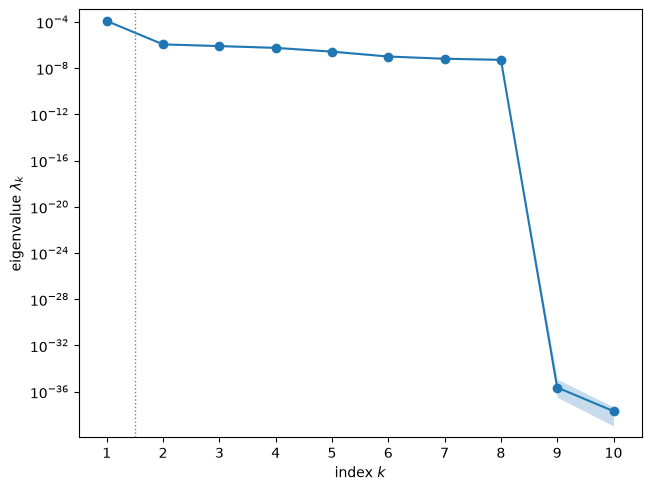

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
fig

The first eigenvalue, $1.213\times10^{-4}$ m$^2$, is 105.49 times the second, and the next ratios are between 1.24 and 2.65, so there is one clear gap; $\lambda_1$ holds 97.558 % of the trace and the other nine 2.442 %. $\lambda_9$ and $\lambda_{10}$ are at the round-off level ($10^{-32}$ and $10^{-34}$ of $\lambda_1$): they are the two exact null directions $\boldsymbol\xi_{E_1} - \boldsymbol\xi_{A_1}$ and $\boldsymbol\xi_{E_2} - \boldsymbol\xi_{A_2}$ of the product structure. The library's eigenvalue-gap rule also picks $n = 1$.

bootstrap mean subspace distance, k = 1..7: [0.0051 0.1116 0.1087 0.0639 0.0476 0.0804 0.1504]


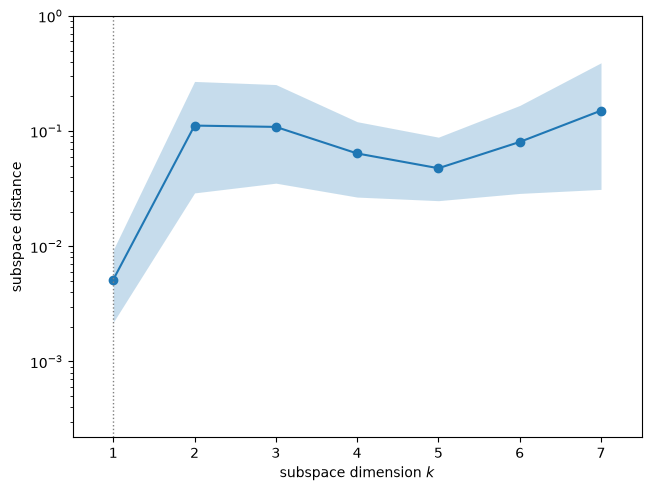

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(sub, k_max=7)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..7:', np.array2string(sub.bootstrap_distances.mean(axis=0)[:7], precision=4))
fig

The bootstrap mean subspace distance is 0.0051 for $k = 1$ and between 0.0476 and 0.1504 for $k = 2, \dots, 7$, so only the one-dimensional subspace is estimated stably; the eigenvalues after the first are close together and their eigenvectors are not well determined from 1000 samples. **Dimension: $n = 1$**, from the gap $\lambda_1/\lambda_2 = 105.49$ (next ratio 1.4), the small $k = 1$ subspace error, the 2.442 % of the trace left out, and the surrogates below (a second active variable raises the leave-one-out $R^2$ of a quadratic only from 0.9873 to 0.9926).

w1: E1 -0.6109, E2 -0.1110, A1 -0.6109, A2 -0.1110, P1 +0.0661, P2 +0.1899, P3 +0.2713, P4 +0.2718, P5 +0.1908, P6 +0.0676
w2: E1 +0.0023, E2 -0.0095, A1 +0.0023, A2 -0.0095, P1 +0.0017, P2 +0.0401, P3 +0.7379, P4 -0.6575, P5 -0.1461, P6 -0.0088
|cos| between w1 and the mean gradient: 0.999991
w1 weight of E1 (or A1) / weight of E2 (or A2): 5.50
P3 - P4 weight in w2: +0.7379 vs -0.6575


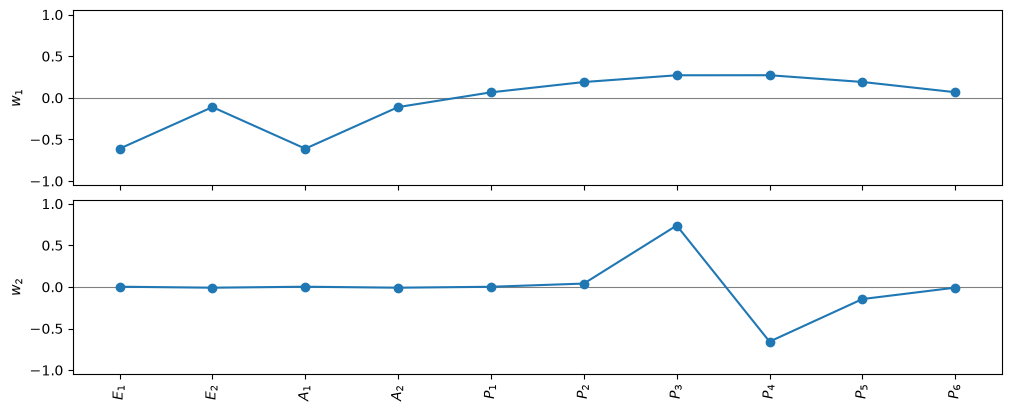

In [8]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(10, 4))
plt.close(fig)
W = sub.W
for k in (0, 1):
    print(f'w{k + 1}:', ', '.join(f'{n} {w:+.4f}' for n, w in zip(tm.NAMES, W[:, k])))
g_bar = G_xi.mean(axis=0)
print(f'|cos| between w1 and the mean gradient: {abs(W[:, 0] @ g_bar) / np.linalg.norm(g_bar):.6f}')
print(f'w1 weight of E1 (or A1) / weight of E2 (or A2): {W[0, 0] / W[1, 0]:.2f}')
print(f'P3 - P4 weight in w2: {W[6, 1]:+.4f} vs {W[7, 1]:+.4f}')
fig

In the order $E_1, E_2, A_1, A_2, P_1, \dots, P_6$, $\mathbf w_1 = (-0.6109, -0.1110, -0.6109, -0.1110, +0.0661, +0.1899, +0.2713, +0.2718, +0.1908, +0.0676)$: stiffer or thicker bars reduce the deflection, larger loads increase it, the horizontal bars outweigh the oblique ones by a factor 5.5, and the load weights are symmetric about midspan and largest for the loads nearest it ($P_3$, $P_4$). Equal weights for $E_1$ and $A_1$ (and $E_2$, $A_2$) are exact, from the product structure. $\mathbf w_1$ is almost the direction of the mean gradient ($|\cos| = 0.999991$), as expected for a nearly linear response. The second eigenvector is mostly the antisymmetric load pair $P_3 - P_4$ (weights $+0.7379$ and $-0.6575$), but its eigenvalue is close to the third and its direction is not stable (bootstrap distance 0.1116 for $k = 2$).

y1 range [-3.33, 3.18]; corr(y1, V1) = 0.9885; corr(y1, ln V1) = 0.9939


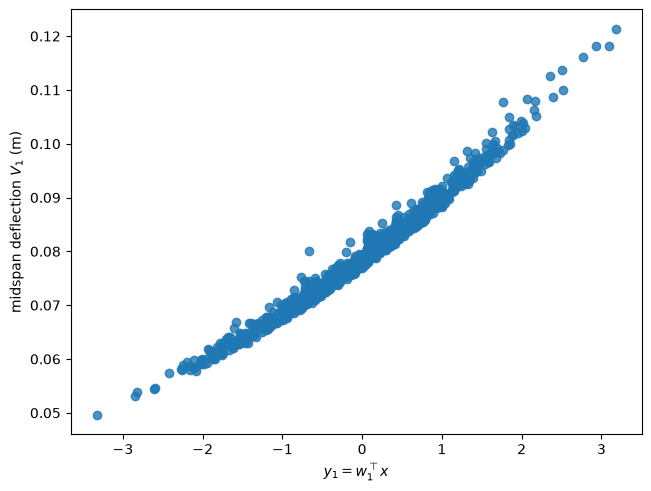

In [9]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=XI, f=V, dims=1, qoi_label=r'midspan deflection $V_1$ (m)')
plt.close(fig)
y1 = XI @ W[:, 0]
print(f'y1 range [{y1.min():.2f}, {y1.max():.2f}]; corr(y1, V1) = {np.corrcoef(y1, V)[0, 1]:.4f}; '
      f'corr(y1, ln V1) = {np.corrcoef(y1, np.log(V))[0, 1]:.4f}')
fig

The first active variable spans $[-3.33, 3.18]$ and $V_1$ rises with it smoothly and slightly convexly (correlation 0.9885 with $V_1$, 0.9939 with $\ln V_1$, because $V_1 \propto 1/(E_1A_1)$ is close to log-linear in the lognormal stiffnesses). The vertical scatter is the variation along the other nine directions, mostly the loads.

**Surrogates.** Polynomials in one and two active variables, with leave-one-out $R^2$; the figure shows the quadratic in $y_1$.

degree 1 in 1 active variable(s): LOO R^2 = 0.9769
degree 2 in 1 active variable(s): LOO R^2 = 0.9873
degree 3 in 1 active variable(s): LOO R^2 = 0.9873
degree 1 in 2 active variable(s): LOO R^2 = 0.9769
degree 2 in 2 active variable(s): LOO R^2 = 0.9926
degree 3 in 2 active variable(s): LOO R^2 = 0.9927


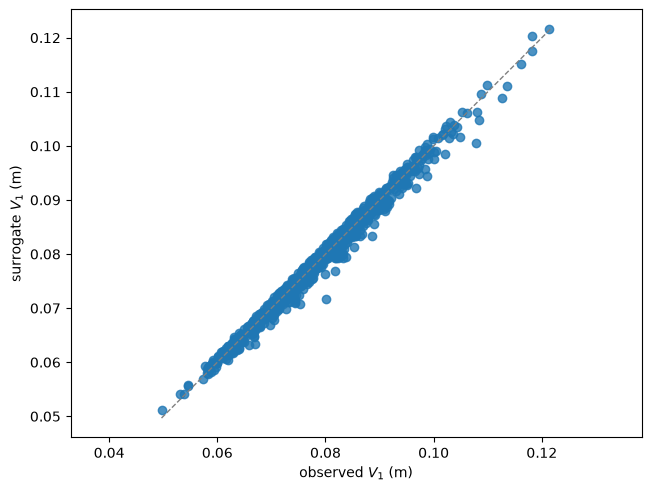

In [10]:
sub2 = ac.active_subspace(space=space, X=XI, f=V, grads=G_xi, estimator='as', n=2)
loo = {}
for n_, s_ in ((1, sub), (2, sub2)):
    for deg in (1, 2, 3):
        loo[n_, deg] = ac.fit_surrogate(X=XI, f=V, space=space, subspace=s_, kind='poly', degree=deg)
        print(f'degree {deg} in {n_} active variable(s): LOO R^2 = {loo[n_, deg].loo_r_squared:.4f}')
fig, ax = ac.plotting.plot_surrogate_fit(loo[1, 2], X=XI, f=V, qoi_label=r'$V_1$ (m)')
plt.close(fig)
fig

In one active variable the leave-one-out $R^2$ is 0.9769 (linear), 0.9873 (quadratic) and 0.9873 (cubic); with two active variables it is 0.9769, 0.9926 and 0.9927. The quadratic in $y_1$ is thus a one-variable surrogate of the ten-input truss that leaves 1.3 % of the variance unexplained; the residual is spread over many nearly equal eigenvalues, not concentrated in a second direction.

### Comparison with the paper

The paper reports total Sobol' indices (Table 2, p. 2358): a reference from crude Monte Carlo with 5 500 000 finite-element runs, and estimates from sparse polynomial chaos (stepwise regression, 60 runs; LAR, 70 runs). It reports no mean or standard deviation of $V_1$ and no active subspace. The cell estimates the total indices with the Jansen estimator from fresh standard-normal samples ($N = 20\,000$ base samples, $N(m+1) = 220\,000$ runs, seed drawn from `SEED`), with 95 % normal-theory intervals of the numerators, the mean and sd of $V_1$, and the normalized activity scores $\alpha_i(1)/\sum_k\alpha_k(1)$, $\alpha_i(1) = \lambda_1 w_{i1}^2$. `check_accuracy.py` repeats the Sobol' computation with $N = 500\,000$ ($5\,500\,000$ runs, the paper's count); its values are in `DATA.md`.

In [11]:
rng = np.random.default_rng(SEED)
N_mc = 20000
A = rng.standard_normal((N_mc, m))
B = rng.standard_normal((N_mc, m))
fA = tm.deflection_xi(A)
var = fA.var(ddof=1)
T = np.empty(m)
hw = np.empty(m)
for i in range(m):
    ABi = A.copy()
    ABi[:, i] = B[:, i]
    d2 = (fA - tm.deflection_xi(ABi))**2 / 2
    T[i], hw[i] = d2.mean() / var, 1.96 * d2.std(ddof=1) / np.sqrt(N_mc) / var
se_var = np.sqrt((np.mean((fA - fA.mean())**4) - var**2) / N_mc)
print(f'mean V1 = {fA.mean():.5f} +- {1.96 * fA.std(ddof=1) / np.sqrt(N_mc):.5f} m, sd = {np.sqrt(var):.5f} m '
      f'(variance known to +- {1.96 * se_var / var * 100:.1f} %)')
alpha = ac.activity_scores(sub, n=1)
alpha_n = alpha / alpha.sum()
paper = {'A1': (0.388, 0.374, 0.374), 'E1': (0.367, 0.378, 0.373), 'P3': (0.075, 0.073, 0.073), 'P4': (0.079, 0.069, 0.079),
         'P5': (0.035, 0.036, 0.034), 'P2': (0.031, 0.037, 0.037), 'A2': (0.014, 0.013, 0.013), 'E2': (0.010, 0.014, 0.012),
         'P6': (0.005, 0.005, 0.004), 'P1': (0.004, 0.005, 0.005)}
print(f"{'input':5s} {'ref.':>6s} {'stepw.':>6s} {'LAR':>6s} | {'Jansen (here)':>17s} {'act. score':>10s}")
for name, (r, s_, l_) in paper.items():
    i = tm.NAMES.index(name)
    print(f'{name:5s} {r:6.3f} {s_:6.3f} {l_:6.3f} | {T[i]:7.4f} +- {hw[i]:.4f} {alpha_n[i]:10.4f}')
print(f'sum of total indices: here {T.sum():.4f}; paper reference {sum(v[0] for v in paper.values()):.3f}')
print(f'max |normalized activity score - Jansen total index|: {np.max(np.abs(alpha_n - T)):.4f}')
ref = np.array([paper[n][0] for n in tm.NAMES])
print(f'max |normalized activity score - paper reference|: {np.max(np.abs(alpha_n - ref)):.4f} '
      f'({tm.NAMES[np.argmax(np.abs(alpha_n - ref))]}); max |Jansen - paper reference|: {np.max(np.abs(T - ref)):.4f} '
      f'({tm.NAMES[np.argmax(np.abs(T - ref))]})')

mean V1 = 0.07939 +- 0.00015 m, sd = 0.01110 m (variance known to +- 2.2 %)
input   ref. stepw.    LAR |     Jansen (here) act. score
A1     0.388  0.374  0.374 |  0.3771 +- 0.0078     0.3732
E1     0.367  0.378  0.373 |  0.3709 +- 0.0077     0.3732
P3     0.075  0.073  0.073 |  0.0767 +- 0.0020     0.0736
P4     0.079  0.069  0.079 |  0.0773 +- 0.0020     0.0739
P5     0.035  0.036  0.034 |  0.0370 +- 0.0010     0.0364
P2     0.031  0.037  0.037 |  0.0372 +- 0.0009     0.0361
A2     0.014  0.013  0.013 |  0.0127 +- 0.0003     0.0123
E2     0.010  0.014  0.012 |  0.0126 +- 0.0003     0.0123
P6     0.005  0.005  0.004 |  0.0048 +- 0.0001     0.0046
P1     0.004  0.005  0.005 |  0.0048 +- 0.0001     0.0044
sum of total indices: here 1.0111; paper reference 1.008
max |normalized activity score - Jansen total index|: 0.0039
max |normalized activity score - paper reference|: 0.0148 (A1); max |Jansen - paper reference|: 0.0109 (A1)


| Quantity | Paper (page) | Notebook |
|---|---|---|
| Mean and sd of $V_1$ | not reported | $0.07939 \pm 0.00015$ m; 0.01110 m ($N = 20\,000$); 0.079417 m and 0.011065 m with $N = 500\,000$ (`check_accuracy.py`, DATA.md) |
| Total Sobol' $A_1$, $E_1$ | reference 0.388, 0.367; LAR 0.374, 0.373 (Table 2, p. 2358) | Jansen $0.3771 \pm 0.0078$, $0.3709 \pm 0.0077$; activity score 0.3732 (both, exactly equal) |
| Total Sobol' $P_3$, $P_4$ | reference 0.075, 0.079; LAR 0.073, 0.079 | $0.0767 \pm 0.0020$, $0.0773 \pm 0.0020$; activity scores 0.0736, 0.0739 |
| Total Sobol' $P_2$, $P_5$ | reference 0.031, 0.035; LAR 0.037, 0.034 | $0.0372 \pm 0.0009$, $0.0370 \pm 0.0010$; 0.0361, 0.0364 |
| Total Sobol' $A_2$, $E_2$ | reference 0.014, 0.010; LAR 0.013, 0.012 | $0.0127 \pm 0.0003$, $0.0126 \pm 0.0003$; 0.0123 (both) |
| Total Sobol' $P_1$, $P_6$ | reference 0.004, 0.005; LAR 0.005, 0.004 | $0.0048 \pm 0.0001$ (both); 0.0044, 0.0046 |
| Sum of total indices | 1.008 (reference column, summed here) | 1.0111 |
| Active subspace | not reported | $n = 1$, $\lambda_1/\lambda_2 = 105.49$, LOO $R^2$ 0.9873 (quadratic) |
| Convergence of full and sparse PC with the number of runs (Fig. 9, p. 2359) | figure | not reproduced (PC convergence; no PC is fitted here) |

The agreement is close for every input, and the model fixes two facts that the paper's reference column does not show. First, $E_1$ and $A_1$ have exactly the same total index (same lognormal coefficient of variation, entering only through $E_1A_1$, as the paper itself explains on p. 2358), so the gap between the reference values 0.388 and 0.367 is estimation error; our own $N = 20\,000$ estimates differ by 0.0062 for the same reason, within their intervals. Its size depends on the estimator. `check_accuracy.py` (check 3) measures the sampling sd of three total-index estimators at the paper's size, $N = 500\,000$ base samples: Jansen's [[4]](#References) has sd 0.0010 for $A_1$ and $E_1$, so the reference's $A_1$ would be 16.1 sd from the true value 0.3711; the Homma–Saltelli form [[5]](#References), $1 - (\overline{f_A f_i} - f_0^2)/V$ (and the Sobol' 2007 form, which coincides with it when $f_0$ and $V$ come from the same sample), has sd 0.0092 for $A_1$ and 0.010 for $E_1$, because $E[V_1]^2/\mathrm{Var}\,V_1 = 51.5$ is large here. Under that estimator every reference entry lies within 2.5 sd of the true value ($A_1$ +1.8, $E_1$ −0.4), so the reference column is consistent with the sampling error of a Homma–Saltelli-type pick-freeze estimator at $N = 5\times10^5$, not with a Jansen estimator of that size (largest deviation 68.7 sd, for $E_2$). Second, by the symmetry of the truss the indices of $P_2$ and $P_5$ are equal; the reference gives 0.031 and 0.035 and the sparse expansions 0.037 and about 0.035, while we find 0.0372 and 0.0370, so the paper's 0.031 for $P_2$ is low: 2.5 sd of a Homma–Saltelli-type estimator below the true value 0.0378, the largest deviation of the ten (`check_accuracy.py`, check 3). The normalized activity scores of the one-dimensional subspace match our Jansen total indices to within 0.0039: the response is nearly additive and nearly linear in $\boldsymbol\xi$, so the squared gradient weights and the variance shares nearly coincide. The total of 5 500 000 runs in the paper equals $N(m+1)$ with $N = 500\,000$, which suggests a pick-freeze design of that size; together with the sampling spreads above it points to a Homma–Saltelli-type estimator (our inference; the paper does not say which estimator it used).

### References

[1] G. Blatman and B. Sudret. [Adaptive sparse polynomial chaos expansion based on least angle regression](https://doi.org/10.1016/j.jcp.2010.12.021). *Journal of Computational Physics*, 230(6):2345–2367, 2011.

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, Philadelphia, 2015.

[3] S. H. Lee and B. M. Kwak. [Response surface augmented moment method for efficient reliability analysis](https://doi.org/10.1016/j.strusafe.2005.08.003). *Structural Safety*, 28(3):261–272, 2006. (Cited by [1] as the source of the truss example, ref. [56]; not opened for this notebook.)

[4] M. J. W. Jansen. [Analysis of variance designs for model output](https://doi.org/10.1016/S0010-4655(98)00154-4). *Computer Physics Communications*, 117(1–2):35–43, 1999. (The total-index estimator used above.)

[5] T. Homma and A. Saltelli. [Importance measures in global sensitivity analysis of nonlinear models](https://doi.org/10.1016/0951-8320(96)00002-6). *Reliability Engineering & System Safety*, 52(1):1–17, 1996.

In [12]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 10.7 s
